In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# Let's take a look at the Pigot data

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM

In [3]:
Plots.theme(:dao)

In [4]:
include("./diversity-simulator.jl")
using .dsim

In [5]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1]

In [6]:
length(cpal10)

47

Import the birds. This is one of many.

In [8]:
read_data = CSV.read("./Pigot2025/Pigot2025/EmpiricalData/Fish_Individual.csv", DataFrame)
gd = groupby(read_data, :Site)

Row,Site,Binomial,Body_Mass,N
,String,String,Float64,Float64
1,palau_1_21,Chlorurus microrhinos,738.76,7.0
2,palau_1_21,Chlorurus microrhinos,339.779,7.0
3,palau_1_21,Scarus rubroviolaceus,738.76,7.0
4,palau_1_21,Scarus spinus,73.3225,7.0
5,palau_1_21,Chlorurus sordidus,62.2522,27.0
6,palau_1_21,Chlorurus sordidus,43.41,13.0
7,palau_1_21,Chlorurus sordidus,73.3225,7.0
8,palau_1_21,Chlorurus sordidus,62.2522,13.0
9,palau_1_21,Chlorurus sordidus,73.3225,7.0


Make a plot of the diversity versus the size.

In [20]:
# scatter(sum.([x[!,:N] for x in gd]), length.([x[!,:N] for x in gd]), xaxis = :log, yaxis = :log, alpha = 0.1)

In [10]:
logxs = log10.(sum.([x[!,:N] for x in gd]))
logys = log10.(length.([x[!,:N] for x in gd]));

In [11]:
df = DataFrame(y = logys, x = logxs);

In [12]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
─────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error       t  Pr(>|t|)  Lower 95%  Upper 95%
─────────────────────────────────────────────────────────────────────────
(Intercept)  0.540279  0.00559493   96.57    <1e-99   0.529312   0.551246
x            0.371864  0.00213117  174.49    <1e-99   0.367686   0.376041
─────────────────────────────────────────────────────────────────────────

In [13]:
coef(glm)

2-element Vector{Float64}:
 0.5402793130437179
 0.3718637667204577

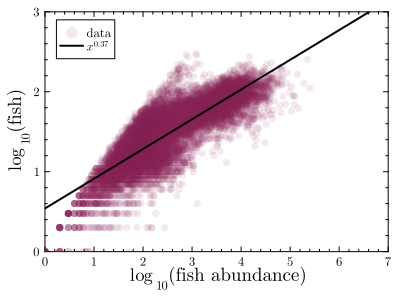

In [26]:
scatter(log10.(sum.([x[!,:N] for x in gd])), log10.(length.([x[!,:N] for x in gd])), alpha = 0.1, label = "data", c = pal[8]);
plot!(collect(0:7),coef(glm)[1] .+ collect(0:7) .*coef(glm)[2], label = L"x^{%$(round(coef(glm)[2],digits = 2))}", color = :black, lw = 2)
plot!(xlims = [0,7], ylims = [0,3], ylabel = L"$\log_{10}$(fish)", xlabel = L"$\log_{10}$(fish abundance)", legend = :topleft,
    size = (400,300), grid = :none, minorgrid = :none)

Now let's make the rank-frequency plots.

In [15]:
si = sortperm(length.([x[!,:N] for x in gd]), rev = true);

In [18]:
cpal = [pal[i] for i in 0.0:1/1000:1];

In [24]:
# scatter(sort(gd[si[1]][!,:N]./sum(gd[si[1]][!,:N]), rev = true), xaxis = :log, yaxis = :log, color = cpal[1], alpha = 0.1)
# for i in 2:1000
#     scatter!(sort(gd[si[i]][!,:N]./sum(gd[si[i]][!,:N]), rev = true), color = cpal[i], alpha = 0.1)
# end
# scatter!(legend = :none, ylabel = "norm. freq.", xlabel = "rank", size = (400,300), grid = :none, minorgrid = :none)